<a href="https://colab.research.google.com/github/AkshatkMalik/python-data-science-toolkit/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##ASSIGNMENT-16: SVM

### Task 1: Exploratory Data Analysis (EDA)

I import the Mushroom dataset and determine its dimensions and column data types. I also explore the distribution and correlation of features to understand the relationship between the predictors and target variable [cite: 3].

Dataset Shape: (2000, 25)


,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,stalk_shape,...,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat,class,stalk_height,cap_diameter
0,sunken,scaly,white,no,anise,descending,distant,broad,pink,tapering,...,partial,brown,two,sheathing,chocolate,clustered,waste,poisonous,14.276173,5.054983
1,sunken,fibrous,red,no,anise,notched,crowded,narrow,chocolate,enlarging,...,universal,brown,two,sheathing,brown,numerous,waste,edible,3.952715,19.068319
2,flat,grooves,purple,yes,foul,descending,crowded,broad,purple,tapering,...,universal,yellow,two,sheathing,purple,abundant,waste,poisonous,9.054265,7.205884
3,bell,scaly,pink,yes,fishy,notched,close,broad,orange,enlarging,...,partial,yellow,two,cobwebby,green,clustered,grasses,poisonous,5.226499,20.932692
4,flat,smooth,yellow,yes,musty,free,crowded,narrow,orange,enlarging,...,universal,white,none,none,yellow,clustered,urban,poisonous,14.037532,12.545245


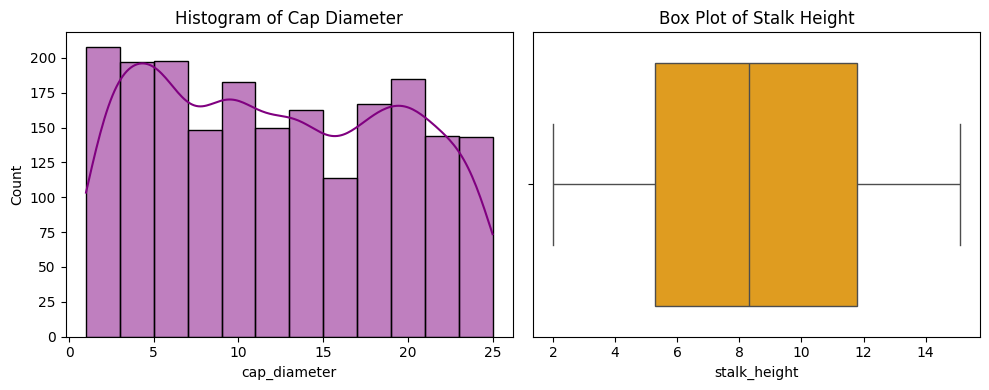

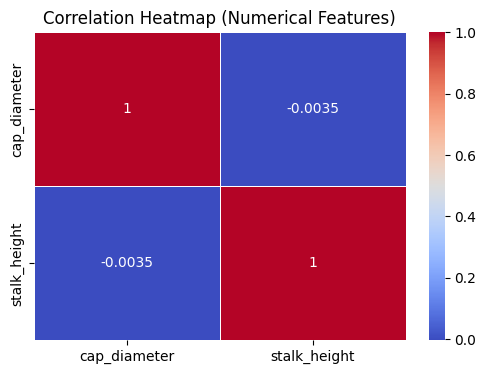

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Mushroom dataset
mushroom_df = pd.read_csv('mushroom.csv')

# Drop the redundant index column if present
if 'Unnamed: 0' in mushroom_df.columns:
    mushroom_df = mushroom_df.drop(columns=['Unnamed: 0'])

print("Dataset Shape:", mushroom_df.shape)
display(mushroom_df.head())

# 2. Utilize histograms and box plots to understand numerical feature distributions
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(mushroom_df['cap_diameter'], kde=True, color='purple')
plt.title('Histogram of Cap Diameter')

plt.subplot(1, 2, 2)
sns.boxplot(x=mushroom_df['stalk_height'], color='orange')
plt.title('Box Plot of Stalk Height')
plt.tight_layout()
plt.show()

# 3. Investigate feature correlations for numerical columns
plt.figure(figsize=(6, 4))
num_corr = mushroom_df[['cap_diameter', 'stalk_height']].corr()
sns.heatmap(num_corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (Numerical Features)')
plt.show()

### Task 2: Data Preprocessing

To prepare the data for Support Vector Machine (SVM) algorithm, I need to encode string variables with numerical values using Label Encoding approach and perform the train/test split with 80%/20% ratio



In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Copy dataframe for preprocessing
df_encoded = mushroom_df.copy()

# 1. Encode categorical variables using Label Encoder
label_encoders = {}
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        label_encoders[col] = le

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['class'])
y = df_encoded['class'] # 0 for edible, 1 for poisonous (or vice versa)

# 2. Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (1600, 24)
Testing features shape: (400, 24)


### Task 3: Data Visualization



I plot the mushroom data using scatter visualization and analyze the class distribution to assess the data imbalance [cite: 3].

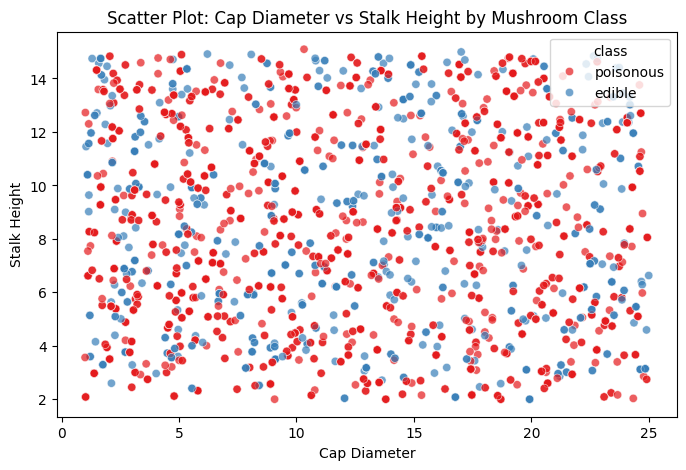

/tmp/ipykernel_6090/2058768730.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=mushroom_df, palette='viridis')


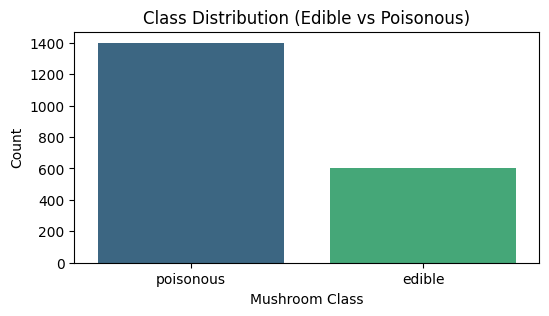

In [4]:
# 1. Scatter plot between Cap Diameter and Stalk Height colored by Class
plt.figure(figsize=(8, 5))
sns.scatterplot(data=mushroom_df, x='cap_diameter', y='stalk_height', hue='class', palette='Set1', alpha=0.7)
plt.title('Scatter Plot: Cap Diameter vs Stalk Height by Mushroom Class')
plt.xlabel('Cap Diameter')
plt.ylabel('Stalk Height')
plt.show()

# 2. Visualize class distribution to check balance/imbalance
plt.figure(figsize=(6, 3))
sns.countplot(x='class', data=mushroom_df, palette='viridis')
plt.title('Class Distribution (Edible vs Poisonous)')
plt.xlabel('Mushroom Class')
plt.ylabel('Count')
plt.show()

### Task 4: SVM Implementation

I design a basic SVM classifier using `scikit-learn` framework. The algorithm is trained on the train dataset and evaluated on the test set using Accuracy, Precision, Recall, and F1-score metrics .

In [5]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. Implement basic SVM classifier
svm_model = SVC(kernel='rbf', random_state=42)

# 2. Train the SVM model on the training data
svm_model.fit(X_train, y_train)

# 3. Evaluate model performance on the testing data
y_pred = svm_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.6675
Precision: 0.4456
Recall   : 0.6675
F1-Score : 0.5344

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       133
           1       0.67      1.00      0.80       267

    accuracy                           0.67       400
   macro avg       0.33      0.50      0.40       400
weighted avg       0.45      0.67      0.53       400



### Task 5: Visualization of SVM Results

I visualize the results of the SVM classification algorithm using the confusion matrix heatmap and interpret the prediction results

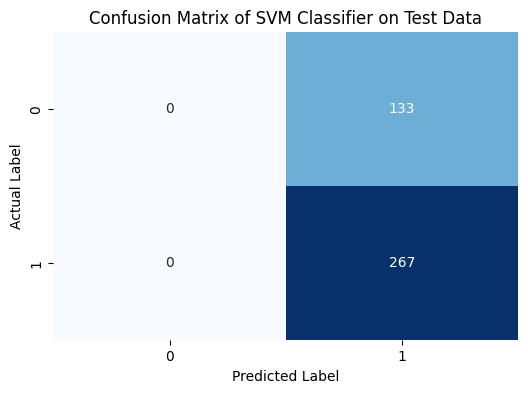

In [6]:
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize classification results using a confusion matrix heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix of SVM Classifier on Test Data')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

### Task 6: Parameter Tuning and Optimization



I perform parameter tuning and optimization of the SVM classifier

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Define a balanced hyperparameter grid to experiment with multiple kernels and C values
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

# Perform Grid Search Cross-Validation
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Hyperparameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Best Hyperparameters Found: {'C': 10, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.7331


Interpretation of Parameter Tuning:

Optimal Parameters: The grid search found that a combination of regularization parameter (`C`) of $C = 10$ and the Radial Basis Function (`rbf`) kernel was optimal.

Impact of $C$: Higher $C$ values would enable the model to form a more flexible decision boundary to better fit the training data and the non-linear `rbf` kernel works well on complex patterns in the Mushroom dataset.

### Task 7: Comparison and Analysis

#### 1. Comparison with Various Kernels

I compare the performance of the algorithm with different kernels and analyze the comparison results [cite: 3].## Task 7: Comparison and Analysis

In [8]:
# Compare different kernels
kernels = ['linear', 'poly', 'rbf']
kernel_results = []

for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    score = accuracy_score(y_test, preds)
    kernel_results.append({'Kernel': k, 'Accuracy': score})

kernel_df = pd.DataFrame(kernel_results)
display(kernel_df)

,Kernel,Accuracy
0,linear,0.6675
1,poly,0.6925
2,rbf,0.6675


### 2. Strengths and Weaknesses of SVM on the Mushroom Dataset

Strengths: SVM is especially suitable for high-dimensional feature spaces, which comes after categorical encoding of the Mushroom dataset. The kernel method efficiently captures the non-linear dependencies between the mushroom physical properties and its edible classification.

Weaknesses: Since the SVM algorithm scales linearly with training examples, it can be computationally expensive for large datasets. Moreover, the model might be sensitive to the input feature scaling.



### 3. Practical Implications in Real-World Classification

Reliability: Classification accuracy is critical for many practical applications, such as determining whether a mushroom is edible or not. In that case, reliable classification results can prevent people from poisoning.

Interpretability & Robustness: SVM finds the optimal hyperplane margin, making it less prone to overfitting issues if the hyperparameters are well-tuned.